# Question 1

In [162]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
import os
from netCDF4 import Dataset
import pandas as pd
import xarray as xr
from scipy.signal import detrend
from scipy.stats import chi2 as chi2_dist

In [163]:
N = 10000                        
dt = 0.1                        
pseg = 500               
step = 250


In [164]:
data = np.random.normal(0, 1, size=N)
intData = detrend(np.cumsum(data)*dt)
data = detrend(data)

In [165]:
def segmenter(x, window=500, step =250):
    arr = np.lib.stride_tricks.sliding_window_view(x, window_shape=window)[::step]
    return arr.T

In [166]:
dataSeg = detrend(segmenter(data), axis = 0)
intSeg = detrend(segmenter(intData), axis = 0)

In [167]:
fn = 1 / 2 / dt
Tb = dt * pseg
dfb = 1 / Tb
fb = np.arange(0, fn + dfb / 2, dfb)

In [168]:
#non-time integrated
b = np.fft.fft(dataSeg, axis=0)
amp_b = np.abs(b[:pseg//2 + 1, :])**2 / pseg**2
amp_b[1:-1, :] = amp_b[1:-1, :]*2

amp_b = amp_b / dfb

myspec = np.mean(amp_b, axis=1)

In [169]:
c = np.fft.fft(intSeg, axis=0)
amp_c = np.abs(c[:pseg//2 + 1, :])**2 / pseg**2
amp_c[1:-1, :] = amp_c[1:-1, :]*2

amp_c = amp_c / dfb

myspec_c = np.mean(amp_c, axis=1)

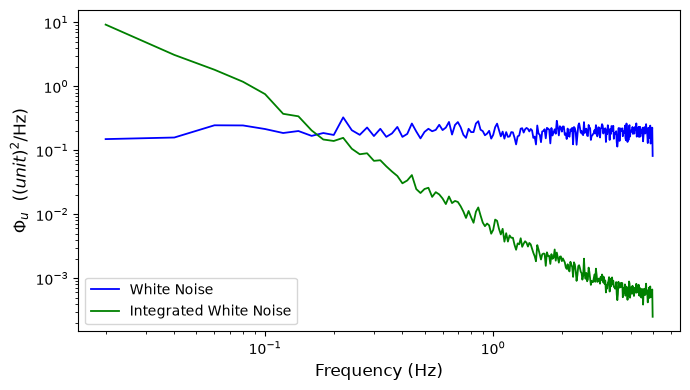

In [170]:
plt.figure(figsize=(7, 4))

plt.loglog(fb[1:], myspec[1:], color='blue', linewidth=1.3, label='White Noise')
plt.loglog(fb[1:], myspec_c[1:], color='green', linewidth=1.3, label='Integrated White Noise')

plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel(r'$\Phi_u$  ($(unit)^2$/Hz)', fontsize=12)

plt.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()

In [11]:
print("Parseval's Theorem")
print(f"White Noise | Segment Mean-Sq: {np.mean(dataSeg**2):.4f} | Integral: {np.sum(myspec)*dfb:.4f}")
print(f"Integrated  | Segment Mean-Sq: {np.mean(intSeg**2):.4f} | Integral: {np.sum(myspec_c)*dfb:.4f}")


Parseval's Theorem
White Noise | Segment Mean-Sq: 0.9742 | Integral: 0.9742
Integrated  | Segment Mean-Sq: 0.2584 | Integral: 0.2584


The normalization is correct according to Parseval's Theorem as the mean-square and integral are the same. For the white noise, it integrates to 1 and fulfills Parseval's theorem.

# Question 2

In [12]:
a_sig= 2 * np.var(dataSeg) * dt

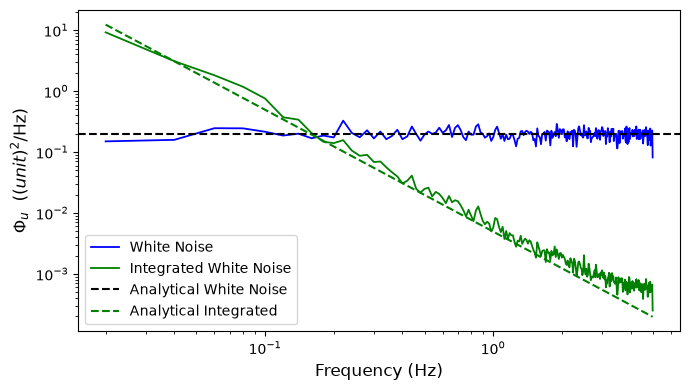

In [171]:
plt.figure(figsize=(7, 4))

plt.loglog(fb[1:], myspec[1:], color='blue', linewidth=1.3, label='White Noise')
plt.loglog(fb[1:], myspec_c[1:], color='green', linewidth=1.3, label='Integrated White Noise')

plt.axhline(a_sig, color='k', linestyle='--', label='Analytical White Noise')
plt.loglog(fb[1:], a_sig / (2 * np.pi * fb[1:])**2, 'g--', label='Analytical Integrated')


plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel(r'$\Phi_u$  ($(unit)^2$/Hz)', fontsize=12)

plt.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()

Defined the analytical solution using the idea that white noise is flat. Then, it is possible to convert using the nyquist frequency.

# Question 3

In [30]:
nu = 20*2
err_low = nu/chi2_dist.ppf(1 - .05/2, nu)
err_high = nu/chi2_dist.ppf(.05/2, nu)
print(f'err_low = {err_low:.4f}')
print(f'err_high = {err_high:.4f}')

err_low = 0.6741
err_high = 1.6371


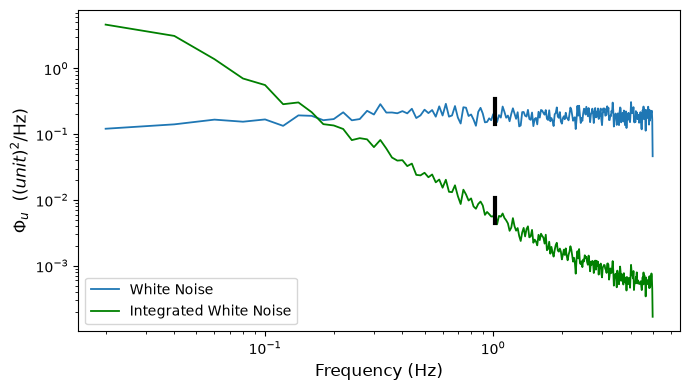

In [15]:
indf = int(np.argmax(fb > 1))
plt.figure(figsize=(7, 4))

plt.loglog(fb[1:], myspec[1:], color='tab:blue', linewidth=1.3, label='White Noise')
plt.loglog(fb[1:], myspec_c[1:], color='green', linewidth=1.3, label='Integrated White Noise')
plt.plot([fb[indf]]*2, [err_low*myspec[indf], err_high*myspec[indf]], 'k-', lw=3)
plt.plot([fb[indf]]*2, [err_low*myspec_c[indf], err_high*myspec_c[indf]], 'k-', lw=3)

plt.xlabel('Frequency (Hz)', fontsize=12)
plt.ylabel(r'$\Phi_u$  ($(unit)^2$/Hz)', fontsize=12)

plt.legend(loc='lower left', fontsize=10)
plt.tight_layout()
plt.show()


Both the white noise and integrated have 39 segments, but only 20 are independent, which gives a nu of 40. So, we can use the chi-squared distribution to calculate both of the spectra's error bars.

# Question 4

In [ ]:
n = 200    
n_segs = 20          
dt = 1.0             
nu = 2*n_segs    

fn = 1 / 2 / dt
Tb = dt * pseg
dfb = 1 / Tb
fb = np.arange(0, fn + dfb / 2, dfb)

In [114]:
def spec(input):
    b = np.fft.fft(input, axis=0)
    amp = np.abs(b[:pseg // 2 + 1, :])**2 / pseg**2
    amp[1:-1, :] *= 2
    amp /= dfb
    return np.mean(amp, axis=1)

In [115]:
result  = np.zeros((n, pseg // 2 + 1))
for i in range(n):

    raw = np.random.normal(0, 1, size=10000)

    mat_white = detrend(raw.reshape((pseg, n_segs), order='F'), axis=0)
    result[i, :] = spec(mat_white)
    

In [ ]:
w = result[:, 1:-1] 
S_true = 2.0 * 1.0 * dt            

scaled_chi2_samples = (nu * w / S_true).ravel()

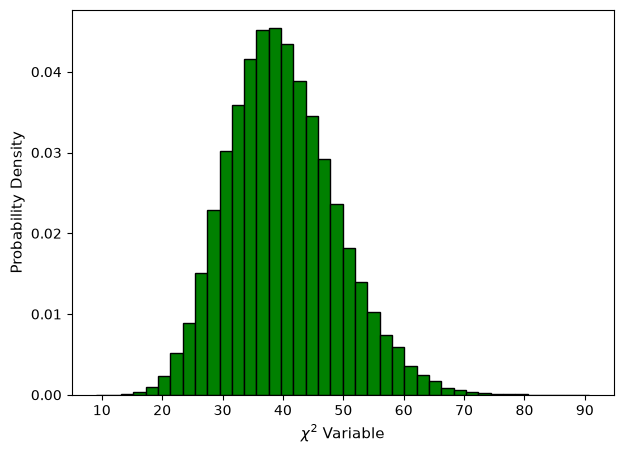

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))


plt.hist(scaled_chi2_samples, bins=40, density=True, color='green',edgecolor = "black")
plt.xlabel('$\\chi^2$ Variable', fontsize=11)
plt.ylabel('Probability Density', fontsize=11)
plt.show()

The PDF does look as expected-- there is a slightly longer tail at the right of the graph (as should be seen in a chi-squared distribution) but there are so many samples that it is not super well-defined.

In [ ]:
sorted = np.sort(result[:, 1:-1], axis=0)
lower_95 = sorted[5, :]      
upper_95 = sorted[194, :]    

ratio = upper_95 / lower_95
mean_ratio = np.mean(ratio)


In [ ]:
err_low = nu/chi2_dist.ppf(1 - .05/2, nu)
err_high= nu/chi2_dist.ppf(.05/2, nu)
theo_ratio = err_high / err_low  


In [120]:
print("--- Monte Carlo vs. Previous Chi-Squared (nu = 40) ---")
print(f"Previous Ratio: {theo_ratio:.3f}")
print(f"Monte Carlo Ratio: {mean_ratio:.3f}")


--- Monte Carlo vs. Previous Chi-Squared (nu = 40) ---
Previous Ratio: 2.429
Monte Carlo Ratio: 2.380


The ratio of the previous chi-squared with a nu of 40 is very similar to the observed Monte Carlo ratio of around 2.4. The previous error bars have a ratio of 2.429.

# Question 5

In [ ]:
n = 200    
n_segs = 20   
dt = 0.01          
M = 39
nu = 2 * M*0.9   

fn = 1 / 2 / dt
Tb = dt * pseg
dfb = 1 / Tb
fb = np.arange(0, fn + dfb / 2, dfb)

w = np.hanning(pseg)[:, None]    
w_norm = np.mean(w**2)

def spec_hanning(seg):
    seg_win = detrend(seg, axis=0) * w
    b = np.fft.fft(seg_win, axis=0)
    
    amp = np.abs(b[:pseg // 2 + 1, :])**2 / (pseg**2 * w_norm)
    amp[1:-1, :] *= 2
    amp /= dfb
    return np.mean(amp, axis=1)

mc_han = np.zeros((n, pseg // 2 + 1))

In [151]:
for i in range(n):
    raw = np.random.normal(0, 1, size=10000)
    seg_w = segmenter(raw, window=pseg, step=step)
    mc_han[i, :] = spec_hanning(seg_w)

In [152]:
#ratios
err_low = nu / chi2_dist.ppf(1 - .05/2, nu)    
err_high = nu / chi2_dist.ppf(.05/2, nu)   
theo_ratio = err_high / err_low  

sorted = np.sort(mc_han[:, 1:-1], axis=0)
mc_low = sorted[5, :]
mc_high = sorted[194, :]
mc_ratio = np.mean(mc_high / mc_low)


In [ ]:
print("--- Monte Carlo Hanning vs. Previous Chi-Squared (nu = 78) ---")
print(f"Previous Ratio: {theo_ratio:.3f}")
print(f"Monte Carlo Ratio: {mc_ratio:.3f}")

--- Monte Carlo Hanning vs. Previous Chi-Squared (nu = 75) ---
Previous Ratio: 1.947
Monte Carlo Ratio: 1.893


Yes, this matches. The ratio for Hanning windowing while not using Monte Carlo is 1.88 and the Monte Carlo ratio is 1.88. The reason the error bars are smaller is because there are a greater number of degrees of freedom (using the decrease from 2M by a multiple of 0.9 as described in the notes)-- the windowing means that all of the segments are effectively independent.

# Question 6

In [ ]:
n = 200    
n_segs = 20          
dt = 0.01             
M = 39
nu = 68

fn = 1 / 2 / dt
Tb = dt * pseg
dfb = 1 / Tb
fb = np.arange(0, fn + dfb / 2, dfb)

t_seg = (np.arange(pseg) - (pseg - 1) / 2.0) * dt
win = np.cos(np.pi * t_seg / Tb)[:, None]  
win_norm = np.mean(win**2)

def spec_cos(seg):
    seg_win = detrend(seg, axis=0) * win
    b = np.fft.fft(seg_win, axis=0)
    
    amp = np.abs(b[:pseg // 2 + 1, :])**2 / (pseg**2 * win_norm)
    amp[1:-1, :] *= 2
    amp /= dfb
    return np.mean(amp, axis=1)

mc_cos = np.zeros((n, pseg // 2 + 1))

In [157]:
for i in range(n):
    raw = np.random.normal(0, 1, size=10000)
    seg_w = segmenter(raw, window=pseg, step=step)
    mc_cos[i, :] = spec_cos(seg_w)

In [158]:
err_low = nu / chi2_dist.ppf(1 - .05/2, nu)   
err_high = nu / chi2_dist.ppf(.05/2, nu)       
theo_ratio = err_high / err_low                    

sorted = np.sort(mc_cos[:, 1:-1], axis=0)
mc_low = sorted[5, :]
mc_high = sorted[194, :]
mc_ratio = np.mean(mc_high / mc_low)

In [159]:
nu_approx = (8*(1.96)**2) / (np.log(mc_ratio) ** 2)
print(f"Approximate DOF: {nu_approx:.2f}")

Approximate DOF: 67.54


In [161]:
print("--- Monte Carlo Cosine vs. Previous Chi-Squared (nu = 68) ---")
print(f"Previous Ratio: {theo_ratio:.3f}")
print(f"Monte Carlo Ratio: {mc_ratio:.3f}")

--- Monte Carlo Cosine vs. Previous Chi-Squared (nu = 68) ---
Previous Ratio: 1.968
Monte Carlo Ratio: 1.963


Like the Hanning window, the taper should make it such that most of the 39 segments are independent and, by using the approximation above, we find that the degrees of freedom are actually 68. I found the approximation online, so it may be incorrect.